# 06 · Actionable use of the explanations: model improvement
**What the explanations told us (notebooks 03–05):**
- `CholCheck`: never having had a cholesterol test *lowers* the predicted risk a lot (SHAP −0.7 to −1.6).
- `HvyAlcoholConsump`: heavy drinking appears *protective* (confounded, not causal).
- `AnyHealthcare`: no coverage lowers the risk.

The label is *diagnosed, self-reported* diabetes, so people who do not see a doctor look "healthy". The model learnt this **detection bias** as if it were medical signal. For a programme that wants to reach people who have **not** been screened this is a problem: the model deprioritises exactly them. Whether that is "wrong" depends on an assumption the data cannot verify (that undiagnosed diabetes is hidden among them), so below we report the trade-off rather than claim a pure improvement.

**Action:** remove the three features, retrain with the same settings, and compare **before vs after** in (1) overall metrics, (2) the explanations, and (3) the groups most affected.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, shap, warnings
from functools import partialmethod
from tqdm import tqdm; tqdm.__init__ = partialmethod(tqdm.__init__, disable=True)
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score
import lightgbm as lgb
from src.preprocess import get_splits
from src.evaluation import threshold_for_recall
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
X_tr, X_va, X_te, y_tr, y_va, y_te = get_splits()
full = joblib.load("../models/lightgbm.joblib")
DROP = ["CholCheck", "HvyAlcoholConsump", "AnyHealthcare"]
keep = [c for c in X_tr.columns if c not in DROP]
params = {**full.get_params(), "n_estimators": 3000}
red = lgb.LGBMClassifier(**params).fit(X_tr[keep], y_tr, eval_set=[(X_va[keep], y_va)], eval_metric="binary_logloss",
                                      callbacks=[lgb.early_stopping(100, verbose=False)])
print("reduced model best iteration:", red.best_iteration_, "| features:", len(keep))
import os; os.makedirs("../models", exist_ok=True); joblib.dump(red, "../models/lightgbm_reduced.joblib")
P = {"full": {s: full.predict_proba(X[X_tr.columns])[:, 1] for s, X in [("val", X_va), ("test", X_te)]},
     "reduced": {s: red.predict_proba(X[keep])[:, 1] for s, X in [("val", X_va), ("test", X_te)]}}

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


reduced model best iteration: 521 | features: 18


## 1. Overall metrics, before vs after
Each model uses its own screening threshold: recall ≥ 80 % on validation (same rule as before). The 95 % CI of the difference comes from a paired bootstrap over test people (300 resamples).

In [2]:
rows = []
thr = {}
for name in ["full", "reduced"]:
    thr[name] = threshold_for_recall(y_va, P[name]["val"], 0.80)
    p = P[name]["test"]; yhat = p >= thr[name]
    rows.append({"model": name, "n_features": 21 if name == "full" else 18, "ROC-AUC": roc_auc_score(y_te, p), "PR-AUC": average_precision_score(y_te, p),
                 "threshold": thr[name], "recall": recall_score(y_te, yhat), "precision": precision_score(y_te, yhat), "F1": f1_score(y_te, yhat), "flagged": yhat.mean()})
tab = pd.DataFrame(rows).set_index("model").round(3); display(tab)
rng = np.random.default_rng(0); yv = y_te.values; n = len(yv); d_auc, d_ap = [], []
for _ in range(300):
    i = rng.integers(0, n, n)
    d_auc.append(roc_auc_score(yv[i], P["reduced"]["test"][i]) - roc_auc_score(yv[i], P["full"]["test"][i]))
    d_ap.append(average_precision_score(yv[i], P["reduced"]["test"][i]) - average_precision_score(yv[i], P["full"]["test"][i]))
for nme, d in [("ROC-AUC", d_auc), ("PR-AUC", d_ap)]:
    print(f"Δ{nme} (reduced − full): {np.mean(d):+.4f}  95% CI [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")

,n_features,ROC-AUC,PR-AUC,threshold,recall,precision,F1,flagged
model,,,,,,,,
full,21,0.818,0.442,0.148,0.799,0.313,0.450,0.390
reduced,18,0.815,0.438,0.147,0.796,0.310,0.446,0.393


ΔROC-AUC (reduced − full): -0.0033  95% CI [-0.0042, -0.0022]
ΔPR-AUC (reduced − full): -0.0048  95% CI [-0.0069, -0.0028]


## 2. Did the explanations change?
SHAP on the same 5,000-row test sample (100-row background). We compare mean |SHAP| of the 18 remaining features, full vs reduced model.

In [3]:
rs = np.random.default_rng(0); idx5k = rs.choice(len(X_te), 5000, replace=False); Xs = X_te.iloc[idx5k]
bg = X_tr.sample(100, random_state=0)
sv_full = shap.TreeExplainer(full, data=bg, feature_perturbation="interventional", model_output="raw")(Xs).values
sv_red = shap.TreeExplainer(red, data=bg[keep], feature_perturbation="interventional", model_output="raw")(Xs[keep]).values
imp_f = pd.Series(np.abs(sv_full).mean(0), index=X_tr.columns); imp_r = pd.Series(np.abs(sv_red).mean(0), index=keep)
cmp = pd.DataFrame({"full": imp_f, "reduced": imp_r}).sort_values("full", ascending=False)
print("Spearman of rankings on the 18 shared features:", round(spearmanr(cmp.dropna()["full"], cmp.dropna()["reduced"])[0], 3))
print("share of total |SHAP| carried by the 3 removed features in the full model: %.1f%%" % (100 * imp_f[DROP].sum() / imp_f.sum()))
cmp.round(3)

 19%|====                | 973/5000 [00:11<00:45]       

 21%|====                | 1068/5000 [00:12<00:44]       

 23%|=====               | 1155/5000 [00:13<00:43]       

 25%|=====               | 1243/5000 [00:14<00:42]       

 27%|=====               | 1333/5000 [00:15<00:41]       

...

 95%|=================== | 4732/5000 [00:42<00:02]       

 97%|=================== | 4844/5000 [00:43<00:01]       

 99%|===================| 4955/5000 [00:44<00:00]       

Spearman of rankings on the 18 shared features: 0.965
share of total |SHAP| carried by the 3 removed features in the full model: 7.3%


,full,reduced
GenHlth,0.503,0.519
Age,0.389,0.409
BMI,0.379,0.387
HighBP,0.349,0.352
HighChol,0.274,0.276
Sex,0.123,0.116
CholCheck,0.119,NaN
Income,0.109,0.099
MentHlth,0.093,0.094
HeartDiseaseorAttack,0.084,0.083


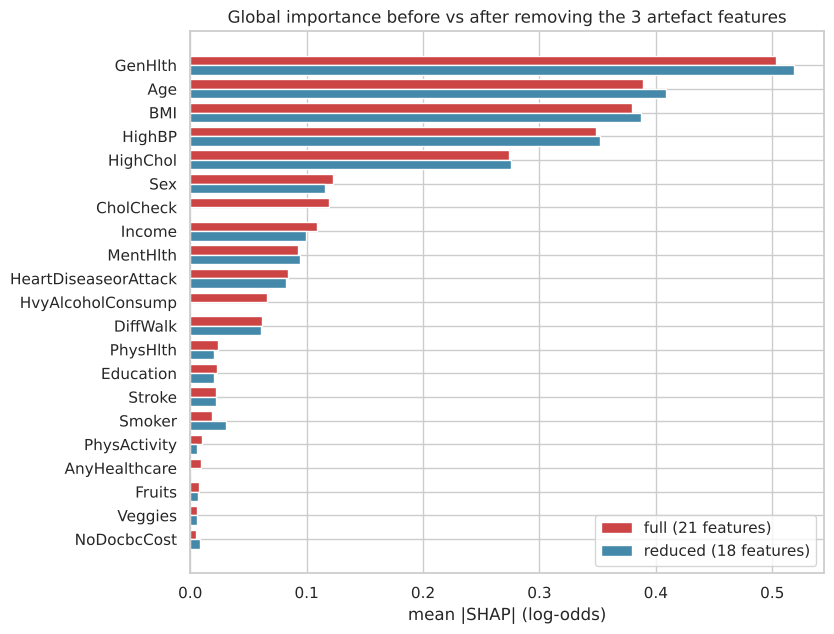

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 6.5)); order = cmp.index[::-1]; y = np.arange(len(order))
ax.barh(y + .2, cmp.loc[order, "full"], .4, label="full (21 features)", color="#c44")
ax.barh(y - .2, cmp.loc[order, "reduced"].fillna(0), .4, label="reduced (18 features)", color="#48a")
ax.set_yticks(y); ax.set_yticklabels(order); ax.set_xlabel("mean |SHAP| (log-odds)"); ax.legend(); ax.set_title("Global importance before vs after removing the 3 artefact features")
plt.tight_layout(); plt.savefig("../figures/action_importance_before_after.png", dpi=150); plt.show()

## 3. Who is affected? Subgroups at the fixed screening rule
People who never had a cholesterol check (`CholCheck = 0`) or have no health coverage (`AnyHealthcare = 0`) are exactly those a screening programme wants to reach.
For each group: prevalence, ROC-AUC, recall and share flagged, full vs reduced (each at its own threshold).

In [5]:
groups = {"everybody": np.ones(len(X_te), bool), "CholCheck = 0 (no cholesterol test)": (X_te.CholCheck == 0).values,
          "AnyHealthcare = 0 (no coverage)": (X_te.AnyHealthcare == 0).values, "HvyAlcoholConsump = 1": (X_te.HvyAlcoholConsump == 1).values,
          "has tested / covered": ((X_te.CholCheck == 1) & (X_te.AnyHealthcare == 1)).values}
rows = []
for g, m in groups.items():
    for name in ["full", "reduced"]:
        p = P[name]["test"][m]; yy = y_te.values[m]; yhat = p >= thr[name]
        rows.append({"group": g, "n": int(m.sum()), "prevalence": yy.mean(), "model": name, "ROC-AUC": roc_auc_score(yy, p) if 0 < yy.mean() < 1 else np.nan,
                     "recall": recall_score(yy, yhat), "precision": precision_score(yy, yhat) if yhat.any() else np.nan, "flagged": yhat.mean(), "mean predicted risk": p.mean()})
sg = pd.DataFrame(rows).round(3); sg

,group,n,prevalence,model,ROC-AUC,recall,precision,flagged,mean predicted risk
0,everybody,34422,0.153,full,0.818,0.799,0.313,0.390,0.155
1,everybody,34422,0.153,reduced,0.815,0.796,0.310,0.393,0.155
2,CholCheck = 0 (no cholesterol test),1380,0.025,full,0.886,0.257,0.225,0.029,0.025
3,CholCheck = 0 (no cholesterol test),1380,0.025,reduced,0.893,0.714,0.130,0.139,0.072
4,AnyHealthcare = 0 (no coverage),1881,0.128,full,0.830,0.729,0.327,0.284,0.117
5,AnyHealthcare = 0 (no coverage),1881,0.128,reduced,0.827,0.754,0.317,0.304,0.128
6,HvyAlcoholConsump = 1,2070,0.058,full,0.796,0.408,0.217,0.109,0.063
7,HvyAlcoholConsump = 1,2070,0.058,reduced,0.788,0.683,0.140,0.283,0.111
8,has tested / covered,31417,0.159,full,0.812,0.806,0.313,0.409,0.162
9,has tested / covered,31417,0.159,reduced,0.810,0.798,0.312,0.407,0.159


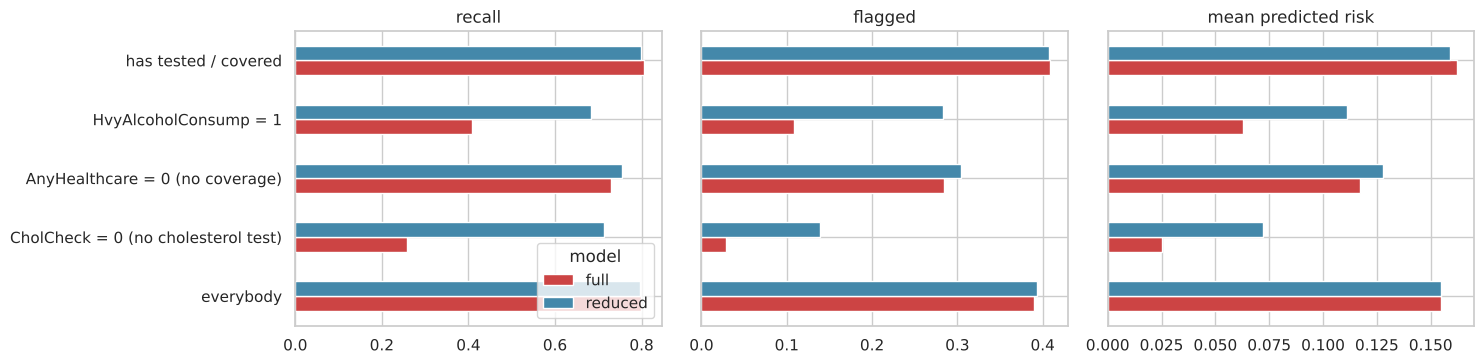

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ["recall", "flagged", "mean predicted risk"]):
    piv = sg.pivot(index="group", columns="model", values=col).loc[list(groups)][["full", "reduced"]]
    piv.plot.barh(ax=ax, color=["#c44", "#48a"], legend=(col == "recall")); ax.set_title(col); ax.set_ylabel("")
    if col != "recall": ax.set_yticklabels([])
plt.tight_layout(); plt.savefig("../figures/action_subgroups.png", dpi=150); plt.show()

## 4. Calibration against the observed labels
Mean predicted risk vs observed rate by `CholCheck`. Note the full model is calibrated for each group *with respect to the diagnosed labels*.

In [7]:
d = pd.DataFrame({"CholCheck": X_te.CholCheck.values, "observed": y_te.values, "pred_full": P["full"]["test"], "pred_reduced": P["reduced"]["test"]})
d.groupby("CholCheck").mean().round(3)

,observed,pred_full,pred_reduced
CholCheck,,,
0,0.025,0.025,0.072
1,0.158,0.160,0.158


## 5. Conclusion
- **Cost of the change is tiny:** ROC-AUC −0.003 (95 % CI roughly [−0.004, −0.002]) and PR-AUC −0.005 overall. The global ranking of the 18 remaining features is almost unchanged (Spearman 0.97): the three removed features carried only ~7 % of the total |SHAP| and their information was largely redundant.
- **Behaviour changes where it matters for the stakeholder:** among people with no cholesterol test, recall at the screening rule goes from 26 % to 71 % (heavy drinkers: 41 % → 68 %), at the price of more false alarms (precision 22 % → 13 %, flagged 3 % → 14 %).
- **But it is a trade-off, not a free win:** against the available (diagnosed, self-reported) labels the full model is better *calibrated* for the unscreened group (predicted 2.5 % vs observed 2.5 %; the reduced model predicts 7.2 %). The reduced model is "better" only if undiagnosed diabetes is hidden in that group, which these data cannot show. The no-test subgroup has only ≈35 positives, so its recall estimates are noisy.
- **Recommendation:** use the reduced model for a screening programme whose aim is to reach people who have not been screened (it does not use access to healthcare as a proxy for health), and keep the full model only if the goal is to predict *diagnosed* diabetes.